## Simple neural network model for image classification on the Imagenette dataset

In this Jupyter notebook we are going to test several basic neural network architectures on the Imagenette dataset. Our aim is to correctly classify the images in the dataset, with an accuracy of at least 60% on the test data.

### Prerequisites

In [1]:
%pip install albumentations

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ExponentialLR
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms
from torchvision.io import read_image
import albumentations as albu

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from functools import partial, reduce
from typing import TypeVar, List, Tuple, Optional, Callable

import warnings

/opt/conda/lib/python3.10/site-packages/albumentations/__init__.py:13: UserWarning: A new version of Albumentations is available: 1.4.21 (you have 1.4.17). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


### Types



In this section, we are defining a series of type sysnonyms, constants and functions for later use.

In [2]:
# TYPES
T = TypeVar('T')

String = str
Bool = bool

# CONSTANTS

# FUNCTIONS
def compose(*funcs):
    return lambda x: reduce(lambda acc, f: f(acc), reversed(funcs), x)

def init(l : List[T]) -> T:
    return l[:-1]

def last(l : List[T]) -> T:
    return l[-1]

### Fetching the data

In [3]:
def get_data_location():
    if os.getcwd() == '/kaggle/working':
        return '../input/imagenette-dataset/dataset/'
    else:
        return 'dataset/'

def read_data() -> Tuple[pd.DataFrame, pd.DataFrame]:
    DATA_LOCATION = get_data_location()
    FILE = DATA_LOCATION + 'noisy_imagenette.csv'
    data = pd.read_csv(FILE).drop(columns = ['noisy_labels_1', 'noisy_labels_5', 'noisy_labels_25', 'noisy_labels_50'])
    resize = albu.Compose([
        albu.Resize(160, 160),
        albu.ToFloat(max_value = 255.0)
    ])

    def process_image(path):
        image = read_image(get_data_location() + path).numpy()  # Convert to NumPy array
        if image.shape[0] == 1:  # If grayscale, convert to RGB
            image = np.repeat(image, 3, axis = 0)

        image = np.transpose(image, (1, 2, 0))  # Change shape from (C, H, W) to (H, W, C)
        image = resize(image = image)['image']  # Apply albumentations resize and normalize
        image = np.transpose(image, (2, 0, 1))  # Change shape back to (C, H, W)
        image = torch.tensor(image).to(torch.float32)  # Convert back to PyTorch tensor

        return image

    data['path'] = data['path'].map(process_image)
    X1 = data.groupby(data.is_valid).get_group(False); X = X1.sample(n = len(X1)).reset_index(drop = True).drop(columns = ['is_valid'])
    y1 = data.groupby(data.is_valid).get_group(True); y = y1.sample(n = len(y1)).reset_index(drop = True).drop(columns = ['is_valid'])
    return X, y



def get_dataloaders() -> Tuple[DataLoader, DataLoader]:
    train, test = read_data()
    encoder = LabelEncoder()
    encoder.fit(train['noisy_labels_0'])

    train['noisy_labels_0'] = encoder.transform(train['noisy_labels_0'])
    test['noisy_labels_0'] = encoder.transform(test['noisy_labels_0'])
    X = DataLoader(list(zip(train['path'], train['noisy_labels_0'])), shuffle = True, batch_size = 16)
    y = DataLoader(list(zip(test['path'], test['noisy_labels_0'])), batch_size = 16)

    return X, y

In [4]:
train_data, test_data = get_dataloaders()

In [6]:
train_data.dataset[0][0]

tensor([[[0.1294, 0.1686, 0.1412,  ..., 0.4627, 0.4627, 0.4627],
         [0.1373, 0.1569, 0.1490,  ..., 0.4627, 0.4627, 0.4627],
         [0.1451, 0.1059, 0.1333,  ..., 0.4627, 0.4627, 0.4627],
         ...,
         [0.4471, 0.4314, 0.4039,  ..., 0.3490, 0.3529, 0.3569],
         [0.4549, 0.4471, 0.4314,  ..., 0.3725, 0.3765, 0.3804],
         [0.4549, 0.4392, 0.4275,  ..., 0.4039, 0.4078, 0.4118]],

        [[0.0471, 0.0941, 0.0667,  ..., 0.3686, 0.3647, 0.3647],
         [0.0627, 0.0863, 0.0824,  ..., 0.3686, 0.3647, 0.3647],
         [0.0784, 0.0471, 0.0745,  ..., 0.3686, 0.3647, 0.3647],
         ...,
         [0.3608, 0.3529, 0.3490,  ..., 0.1961, 0.2000, 0.2039],
         [0.3686, 0.3686, 0.3765,  ..., 0.2275, 0.2314, 0.2353],
         [0.3608, 0.3608, 0.3647,  ..., 0.2588, 0.2627, 0.2667]],

        [[0.0667, 0.1020, 0.0745,  ..., 0.2745, 0.2784, 0.2863],
         [0.0784, 0.0941, 0.0863,  ..., 0.2745, 0.2784, 0.2824],
         [0.0941, 0.0471, 0.0784,  ..., 0.2745, 0.2784, 0.

In [7]:
test_data.dataset[0][0]

tensor([[[0.5804, 0.6000, 0.6392,  ..., 0.3569, 0.3804, 0.4039],
         [0.5922, 0.6039, 0.5922,  ..., 0.3529, 0.4196, 0.4314],
         [0.6078, 0.6118, 0.5490,  ..., 0.3255, 0.3922, 0.4235],
         ...,
         [0.2902, 0.3451, 0.2745,  ..., 0.3843, 0.4039, 0.4039],
         [0.3373, 0.3725, 0.2941,  ..., 0.3529, 0.3647, 0.3765],
         [0.4314, 0.3765, 0.3098,  ..., 0.3686, 0.3647, 0.3922]],

        [[0.5608, 0.5804, 0.6235,  ..., 0.3176, 0.3412, 0.3647],
         [0.5725, 0.5882, 0.5765,  ..., 0.3333, 0.4000, 0.4118],
         [0.5922, 0.5961, 0.5333,  ..., 0.3294, 0.3961, 0.4275],
         ...,
         [0.3333, 0.3922, 0.3255,  ..., 0.4196, 0.4392, 0.4392],
         [0.3804, 0.4196, 0.3451,  ..., 0.3882, 0.4039, 0.4157],
         [0.4745, 0.4235, 0.3686,  ..., 0.4039, 0.4000, 0.4275]],

        [[0.5843, 0.6000, 0.6196,  ..., 0.2118, 0.2353, 0.2588],
         [0.5922, 0.6000, 0.5725,  ..., 0.2196, 0.2863, 0.2980],
         [0.5961, 0.5961, 0.5216,  ..., 0.2078, 0.2745, 0.

### The basic neural network architecture

The architecture we are going to use as basis for our experiments is a convolutional neural network with 3 convolutional layers and 2 linear layers at the end.

In [5]:
class NeuralNet(nn.Module):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    def __init__(self, data : DataLoader, batch_norm : Bool, dropout : Bool) -> None:
        super(NeuralNet, self).__init__()
        self.loader = data
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size = 3, stride = 1, padding = 1),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size = 2, stride = 2),
            nn.Conv2d(16, 32, kernel_size = 3, stride = 1),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size = 2, stride = 2),
            nn.Conv2d(32, 64, kernel_size = 3, stride = 1),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size = 2, stride = 2),
            (nn.BatchNorm2d(64) if batch_norm else nn.Identity()),
            nn.Flatten(),
            nn.Linear(64 * 18 * 18, 128),
            nn.ReLU(),
            (nn.Dropout(0.3) if dropout else nn.Identity()),
            nn.Linear(128, 10)
        ).to(NeuralNet.device)

    def forward(self, x):
        x = x.type(self.net[0].weight.dtype)
        out = self.net(x)
        return out

    def fit(self, epochs : int = 20) -> None:
        optimizer = torch.optim.SGD(self.parameters(), lr = 7e-4, momentum = 0.9)
        criterion = nn.CrossEntropyLoss()

        self.train()

        for epoch in range(epochs):
            losses = []

            for batch_no, input_data in enumerate(self.loader):
                optimizer.zero_grad()
                x, y = input_data
                x = x.clone().detach().to(self.device)
                y = y.clone().detach().to(self.device).long()

                output = self.forward(x)
                loss = criterion(output, y)
                loss.backward()
                losses.append(loss.item())

                optimizer.step()

            print('Epoch %d | Loss %6.2f' % (epoch + 1, sum(losses) / len(losses)))


    def predict(self, data_loader: DataLoader):
        self.eval()
        all_preds = []
        all_labels = []
    
        with torch.no_grad():
            for inputs, labels in data_loader:
                inputs = inputs.to(NeuralNet.device)
                outputs = self.forward(inputs)
                
                _, predicted = torch.max(outputs, 1)
                
                all_preds.extend(predicted.cpu().numpy().tolist())
                all_labels.extend(labels.cpu().numpy().tolist())
    
        all_preds = np.array(all_preds, dtype = int)
        all_labels = np.array(all_labels, dtype = int)
    
        # Print statistics
        print("Classification_report:\n")
        print(classification_report(all_labels, all_preds, digits = 4))
        print("Confusion matrix:\n")
        matrix = confusion_matrix(all_labels, all_preds)
        disp = ConfusionMatrixDisplay(matrix)
        disp.plot()
        plt.show()



    def fit_predict(self, epochs : int, test_data : DataLoader) -> Tuple[List[float], List[float], List[float], List[float]]:
        optimizer = torch.optim.SGD(self.parameters(), lr = 7e-4, momentum = 0.9)
        criterion = nn.CrossEntropyLoss()
        
        train_losses = []
        train_accuracies = []
        test_losses = []
        test_accuracies = []

        for epoch in range(epochs):
            self.train()
            
            losses = []
            correct = 0
            total = 0

            for batch_no, input_data in enumerate(self.loader):
                optimizer.zero_grad()
                x, y = input_data
                x = x.clone().detach().to(self.device)
                y = y.clone().detach().to(self.device).long()

                output = self.forward(x)
                loss = criterion(output, y)
                loss.backward()
                losses.append(loss.item())
                optimizer.step()

                _, predicted = torch.max(output, 1)

                correct += (predicted == y).sum().item()
                total += y.size(0)


            train_losses.append(sum(losses) / len(losses))
            train_accuracies.append(correct / total)

            self.eval()

            test_losses_1 = []
            correct = 0
            total = 0

            with torch.no_grad():
                for t in test_data:
                    x = t[0].clone().detach().to(NeuralNet.device)
                    y = torch.tensor(t[1]).to(NeuralNet.device).long()

                    raw_output = self.forward(x).float()
                    loss = criterion(raw_output, y)
                    test_losses_1.append(loss.item())

                    _, output = torch.max(raw_output, 1)

                    correct += (output == y).sum().item()
                    total += y.size(0)

            test_losses.append(sum(test_losses_1) / len(test_losses_1))
            test_accuracies.append(correct / total)

        return train_losses, train_accuracies, test_losses, test_accuracies

### Functions that run the experiments

Epoch 1 | Loss   2.27
Epoch 2 | Loss   2.05
Epoch 3 | Loss   1.89
Epoch 4 | Loss   1.79
Epoch 5 | Loss   1.71
Epoch 6 | Loss   1.64
Epoch 7 | Loss   1.55
Epoch 8 | Loss   1.47
Epoch 9 | Loss   1.39
Epoch 10 | Loss   1.28
Epoch 11 | Loss   1.18
Epoch 12 | Loss   1.06
Epoch 13 | Loss   0.94
Epoch 14 | Loss   0.83
Epoch 15 | Loss   0.69
Epoch 16 | Loss   0.56
Epoch 17 | Loss   0.42
Epoch 18 | Loss   0.33
Epoch 19 | Loss   0.23
Epoch 20 | Loss   0.18
Epoch 21 | Loss   0.15
Epoch 22 | Loss   0.12
Epoch 23 | Loss   0.09
Epoch 24 | Loss   0.05
Epoch 25 | Loss   0.03
Epoch 26 | Loss   0.01
Epoch 27 | Loss   0.01
Epoch 28 | Loss   0.01
Epoch 29 | Loss   0.00
Epoch 30 | Loss   0.00
Classification_report:

              precision    recall  f1-score   support

           0     0.7026    0.6899    0.6962       387
           1     0.5325    0.5190    0.5256       395
           2     0.6026    0.6499    0.6253       357
           3     0.3889    0.3446    0.3654       386
           4     0.5286 

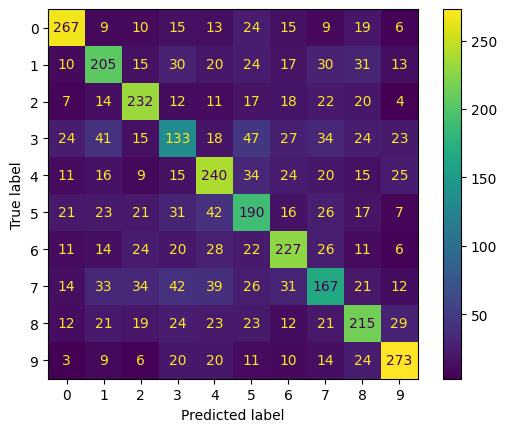

In [6]:
model = NeuralNet(train_data, batch_norm = False, dropout = False)
model.fit(epochs = 30)
model.predict(test_data)

In [14]:
# for the data augmentation part (the albumentations library is used)

class AugmentedDataset(Dataset):
    def __init__(self, dataset, transform = None):
        self.dataset = ConcatDataset([dataset, dataset])
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset[idx]
        if self.transform and idx % 2 == 1:
            augmented = self.transform(image = image)
            image = augmented['image']

        return image, label

def plot_with_without_normalization(mode : String) -> None:
    model1 = NeuralNet(train_data, batch_norm = False, dropout = False).to(NeuralNet.device)
    model2 = NeuralNet(train_data, batch_norm = True if mode == 'normalization' else False, dropout = True if mode == 'dropout' else False).to(NeuralNet.device)
    train_losses1, train_accuracies1, test_losses1, test_accuracies1 = model1.fit_predict(30, test_data)
    train_losses2, train_accuracies2, test_losses2, test_accuracies2 = model2.fit_predict(30, test_data)
    
    # plot the train and test losses
    plt.figure(figsize = (15, 9))
    plt.plot(train_losses1, label = f'train_loss_no_{mode}')
    plt.plot(train_losses2, label = f'train_loss_with_{mode}')
    plt.plot(test_losses1, label = f'test_loss_no_{mode}')
    plt.plot(test_losses2, label = f'test_loss_with_{mode}')
    plt.legend()
    plt.show() 
    plt.clf()

    # plot the train and test accuracies
    plt.figure(figsize = (15, 9))
    plt.plot(train_accuracies1, label = f'train_accuracy_no_{mode}')
    plt.plot(train_accuracies2, label = f'train_accuracy_with_{mode}')
    plt.plot(test_accuracies1, label = f'test_accuracy_no_{mode}')
    plt.plot(test_accuracies2, label = f'test_accuracy_with_{mode}')
    plt.legend()
    plt.show()
    plt.clf()
    print(f"Test accuracy without {mode}: {test_accuracies1[-1]}")
    print(f"Test accuracy with {mode}: {test_accuracies2[-1]}")

def plot_with_without_data_augmentation() -> None:
    jitter = albu.Compose([
        albu.ColorJitter(brightness = 0.2, contrast = 0.2, saturation = 0.2, hue = 0.2),
        albu.HorizontalFlip(p = 1)
    ])
    augmented_train_data = AugmentedDataset(train_data.dataset, transform = jitter)
    new_train_data = DataLoader(augmented_train_data.dataset, shuffle = True, batch_size = train_data.batch_size)
    model1 = NeuralNet(train_data, batch_norm = False, dropout = False).to(NeuralNet.device)
    model2 = NeuralNet(new_train_data, batch_norm = False, dropout = False).to(NeuralNet.device)
    train_losses1, train_accuracies1, test_losses1, test_accuracies1 = model1.fit_predict(30, test_data)    
    train_losses2, train_accuracies2, test_losses2, test_accuracies2 = model2.fit_predict(30, test_data)

    # plot the train and test losses
    plt.figure(figsize = (15, 9))
    plt.plot(train_losses1, label = 'train_loss_no_data_augmentation', color = 'blue')
    plt.plot(train_losses2, label = 'train_loss_with_data_augmentation', color = 'orange')
    plt.plot(test_losses1, label = 'test_loss_no_data_augmentation', color = 'red')
    plt.plot(test_losses2, label = 'test_loss_with_data_augmentation', color = 'green')
    plt.legend()
    plt.show() 
    plt.clf()

    # plot the train and test accuracies
    plt.figure(figsize = (15, 9))
    plt.plot(train_accuracies1, label = 'train_accuracy_no_data_augmentation', color = 'blue')
    plt.plot(train_accuracies2, label = 'train_accuracy_with_data_augmentation', color = 'orange')
    plt.plot(test_accuracies1, label = 'test_accuracy_no_data_augmentation', color = 'red')
    plt.plot(test_accuracies2, label = 'test_accuracy_with_data_augmentation', color = 'green')
    plt.legend()
    plt.show()
    plt.clf()
    print(f"Test accuracy without data augmentation: {test_accuracies1[-1]}")
    print(f"Test accuracy with data augmentation: {test_accuracies2[-1]}")


def plot_with_everything() -> None:
    jitter = albu.Compose([
        albu.ColorJitter(brightness = 0.2, contrast = 0.2, saturation = 0.2, hue = 0.2),
        albu.HorizontalFlip(p = 1)
    ])
    augmented_train_data = AugmentedDataset(train_data.dataset, transform = jitter)
    new_train_data = DataLoader(augmented_train_data.dataset, shuffle = True, batch_size = train_data.batch_size)
    model1 = NeuralNet(new_train_data, batch_norm = False, dropout = False).to(NeuralNet.device)
    train_losses1, train_accuracies1, test_losses1, test_accuracies1 = model1.fit_predict(30, test_data)

    # plot the train and test losses
    plt.figure(figsize = (15, 9))
    plt.plot(train_losses1, label = 'train_loss_with_everything', color = 'blue')
    plt.plot(test_losses1, label = 'test_loss_with_everything', color = 'red')
    plt.legend()
    plt.show() 
    plt.clf()
    
    # plot the train and test accuracies
    plt.figure(figsize = (15, 9))
    plt.plot(train_accuracies1, label = 'train_accuracy_with_everything', color = 'orange')
    plt.plot(test_accuracies1, label = 'test_accuracy_with_everything', color = 'green')
    plt.legend()
    plt.show()
    plt.clf()
    print(f"Test accuracy with everything: {test_accuracies1[-1]}")

/tmp/ipykernel_30/1705679749.py:130: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(t[1]).to(NeuralNet.device).long()


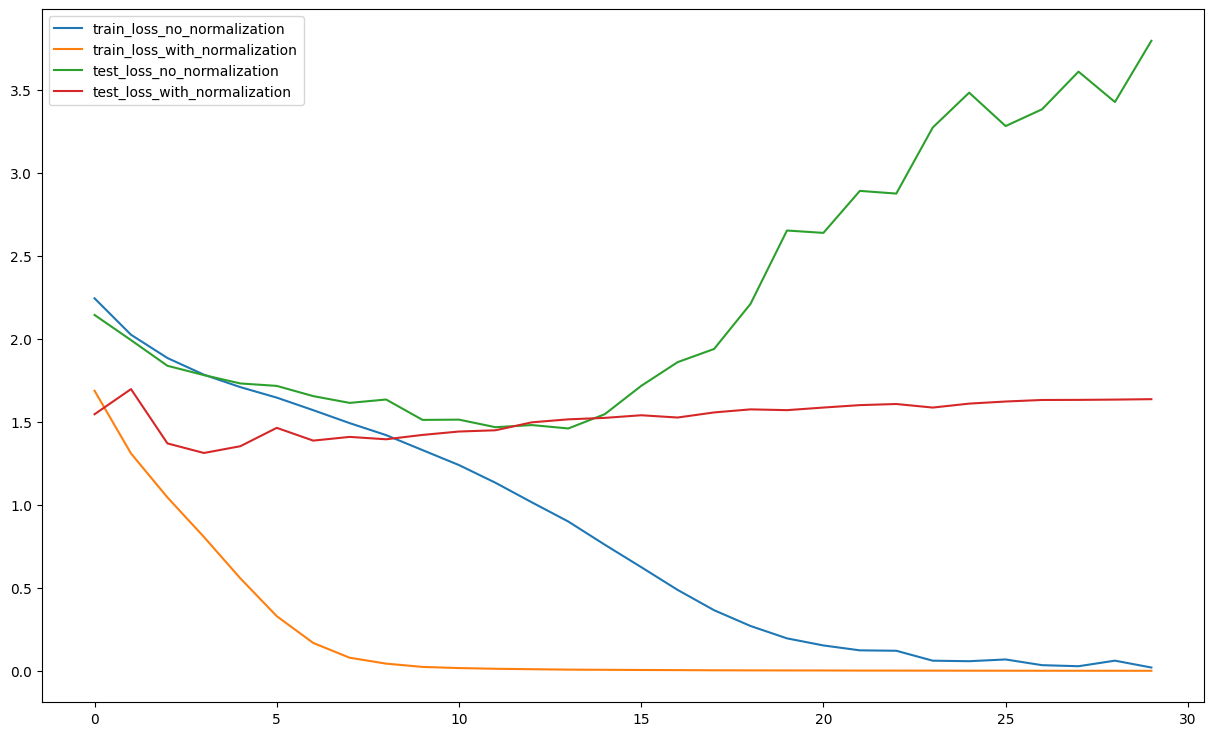

<Figure size 640x480 with 0 Axes>

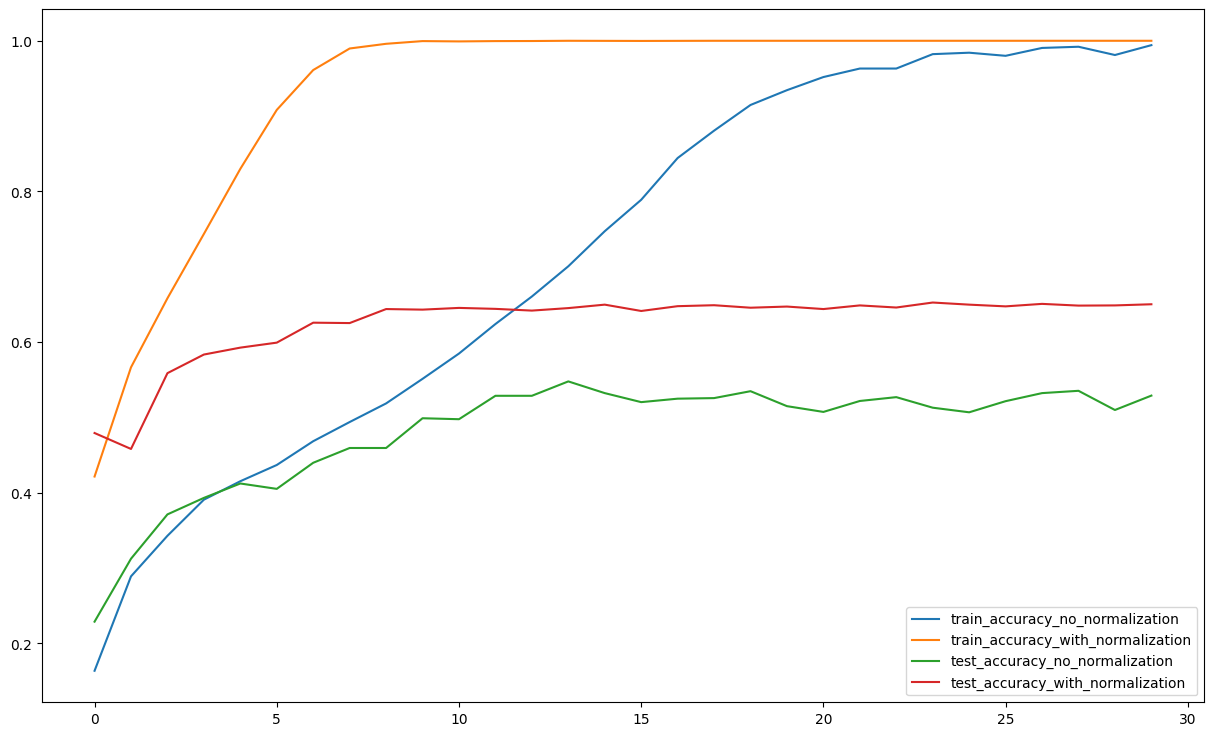

Test accuracy without normalization: 0.5289171974522293
Test accuracy with normalization: 0.6501910828025478


<Figure size 640x480 with 0 Axes>

In [10]:
plot_with_without_normalization('normalization')

/tmp/ipykernel_30/1705679749.py:130: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(t[1]).to(NeuralNet.device).long()


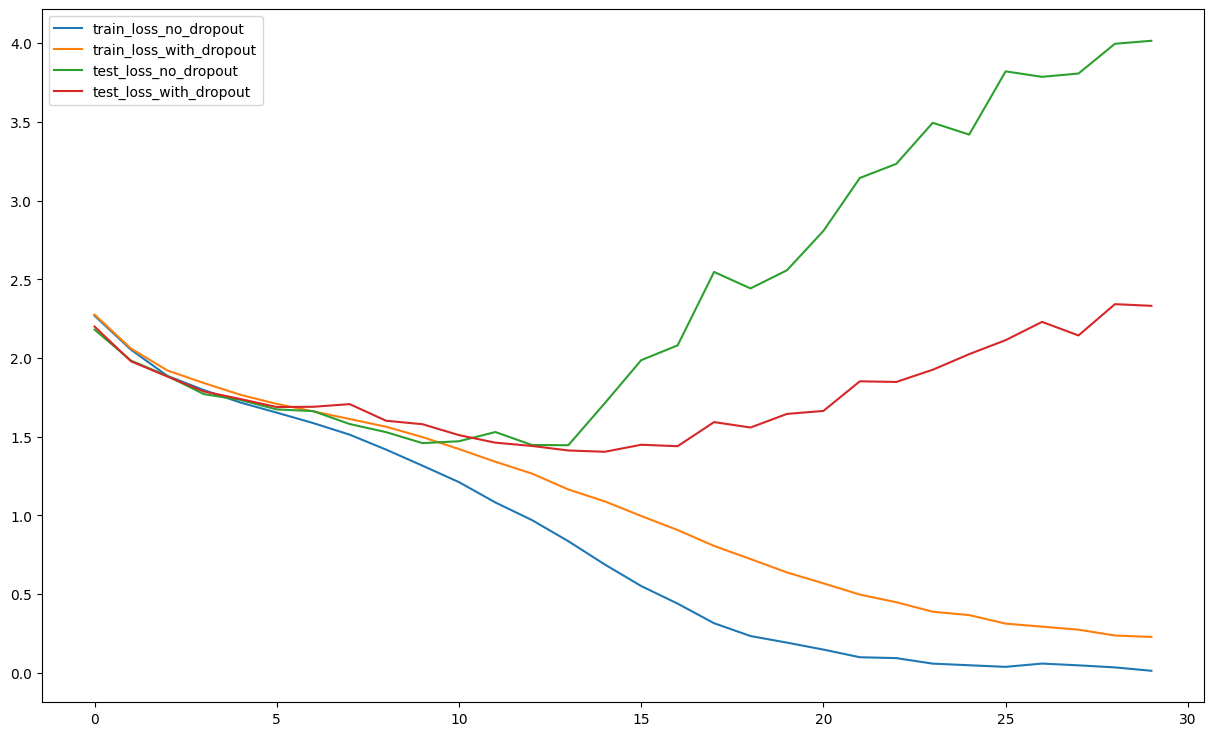

<Figure size 640x480 with 0 Axes>

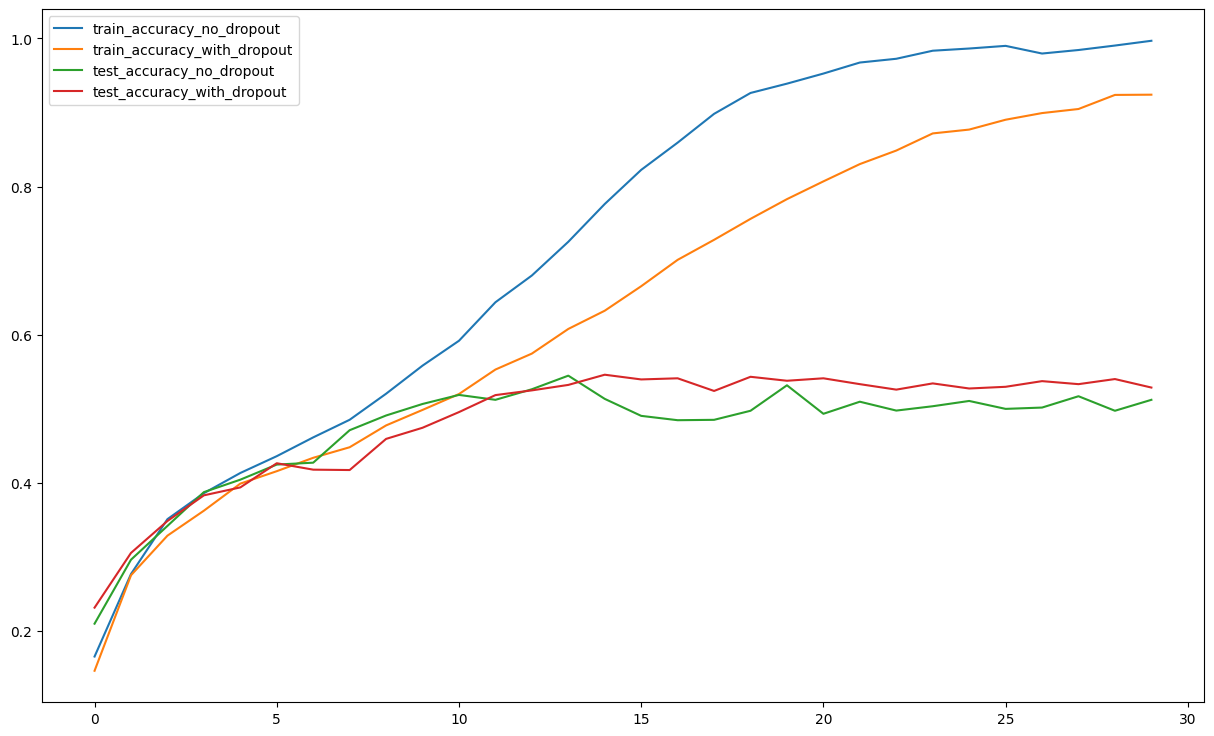

Test accuracy without dropout: 0.5121019108280255
Test accuracy with dropout: 0.5286624203821656


<Figure size 640x480 with 0 Axes>

In [11]:
plot_with_without_normalization('dropout')

/tmp/ipykernel_30/1705679749.py:130: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(t[1]).to(NeuralNet.device).long()


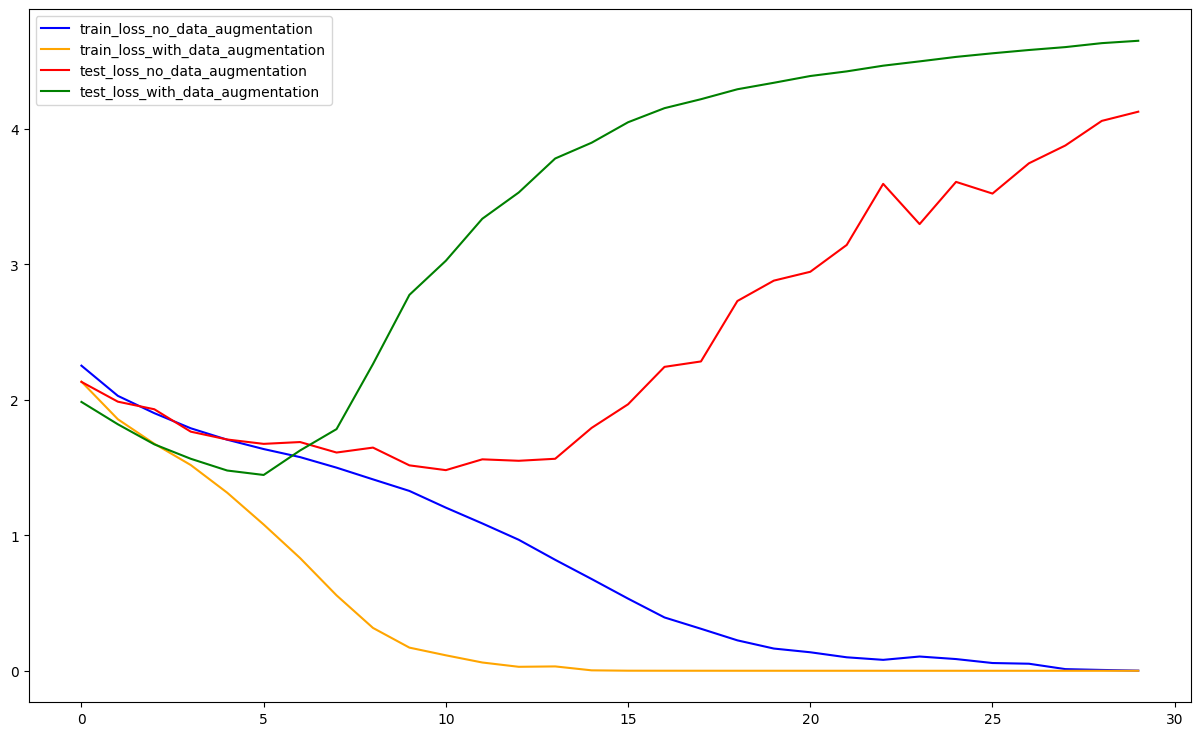

<Figure size 640x480 with 0 Axes>

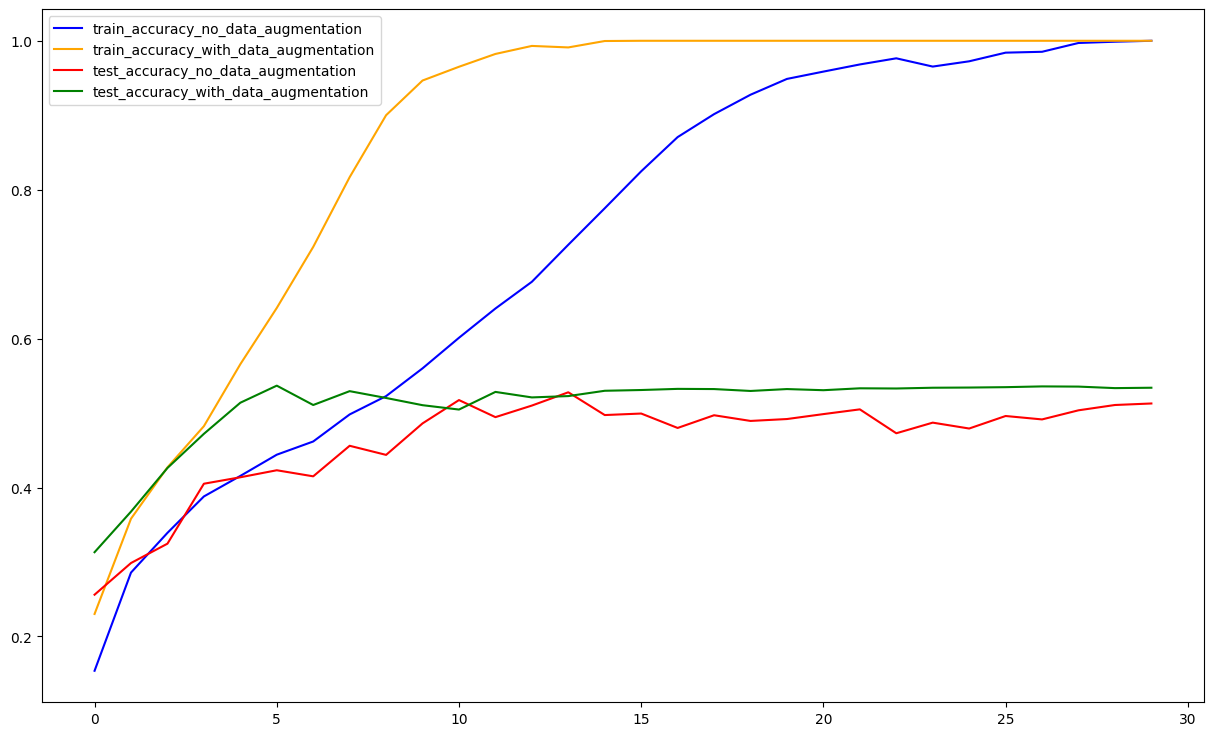

Test accuracy without data augmentation: 0.5128662420382165
Test accuracy with data augmentation: 0.5340127388535032


<Figure size 640x480 with 0 Axes>

In [15]:
plot_with_without_data_augmentation()

/tmp/ipykernel_30/1705679749.py:130: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(t[1]).to(NeuralNet.device).long()


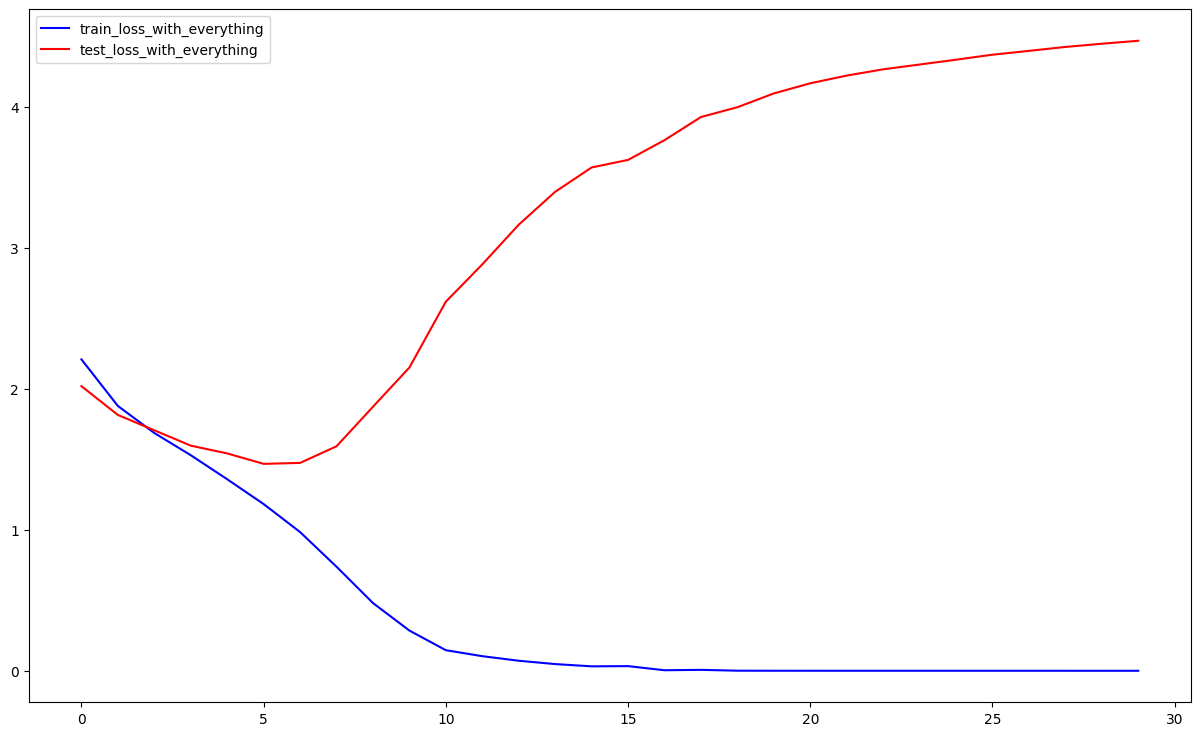

<Figure size 640x480 with 0 Axes>

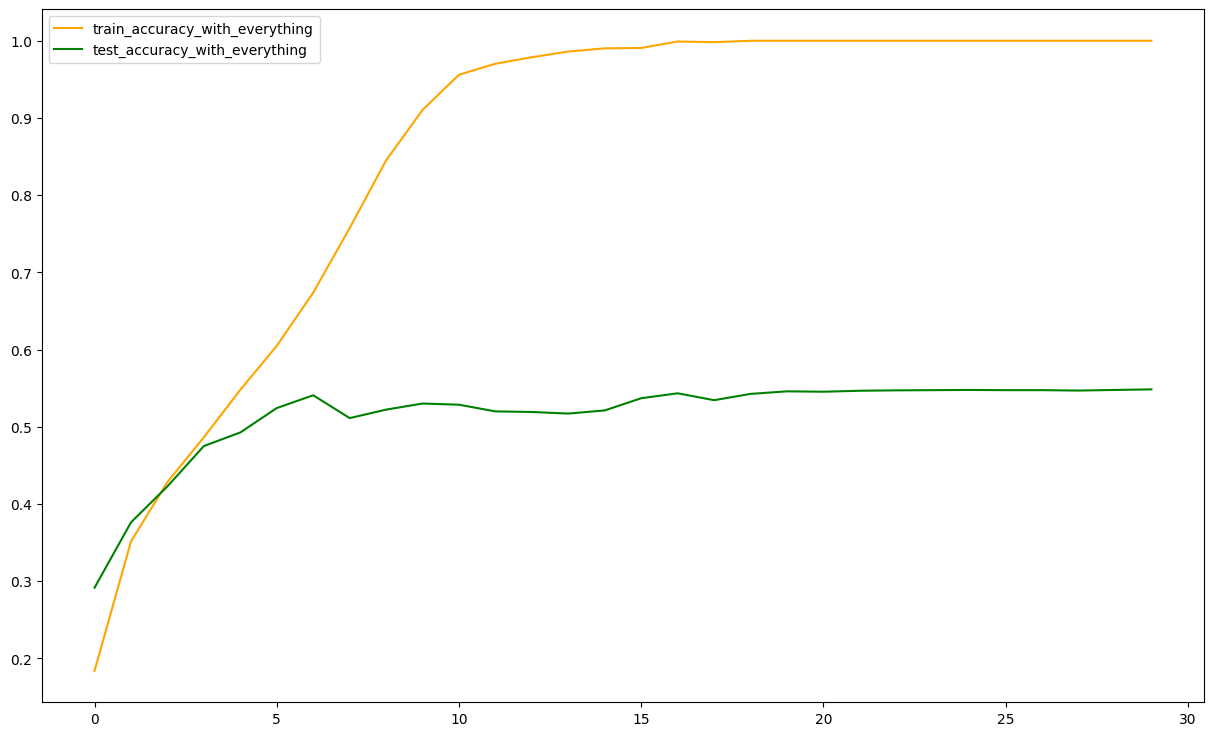

Test accuracy with everything: 0.5485350318471337


<Figure size 640x480 with 0 Axes>

In [16]:
plot_with_everything()